# Fake News Detection — Data Understanding and Quality Assessment

## Project Objective

This notebook establishes a reliable starting point for the Fake News Detection project.

The dataset contains news articles labelled as `Fake` or `True`. The purpose of this stage is not to train a classifier yet, but to understand the data, identify quality issues, examine the text and metadata, and prepare a clean dataset for downstream NLP modelling.

The analysis focuses on:

- dataset structure and schema
- missing and empty values
- duplicate and conflicting articles
- class distribution
- article length and text availability
- subject and date coverage
- preparation of a modelling-ready text field

The raw dataset is kept unchanged. Any cleaning performed here is applied to a separate modelling dataset so that the original source files remain available for reproducibility.

## 1. Environment and Analysis Setup

The analysis uses Python and standard data science libraries. Reproducibility is supported through a fixed project structure and a common random seed that will also be used in later notebooks.

In [4]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

print("Libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully.
Random state: 42


## 2. Project Paths

The notebook is designed to locate the project root automatically instead of relying on a hard-coded absolute path.

This makes the notebook easier to reproduce on another machine while keeping the expected project structure consistent.

In [5]:
def find_project_root():
    current = Path.cwd().resolve()

    candidates = [
        current,
        current.parent,
        current.parent.parent,
    ]

    for candidate in candidates:
        if (
            (candidate / "data" / "raw").exists()
            and (candidate / "notebooks").exists()
            and (candidate / "src").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the Fake-News-Detection project root. "
        "Make sure the notebook is inside the project's notebooks folder."
    )


PROJECT_ROOT = find_project_root()

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:")
print(PROJECT_ROOT)

print("\nRaw data directory:")
print(RAW_DATA_DIR)

print("\nReports directory:")
print(REPORTS_DIR)

Project root:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection

Raw data directory:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\data\raw

Reports directory:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports


## 3. Dataset Files

The project uses the two source files supplied with the Fake and Real News dataset:

- `Fake.csv`
- `True.csv`

These files are treated as raw input and are not modified directly.

In [6]:
FAKE_PATH = RAW_DATA_DIR / "Fake.csv"
TRUE_PATH = RAW_DATA_DIR / "True.csv"

missing_files = [
    str(path)
    for path in [FAKE_PATH, TRUE_PATH]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required dataset file(s) were not found:\n"
        + "\n".join(missing_files)
        + "\n\n"
        "Expected location:\n"
        f"{RAW_DATA_DIR}"
    )

print("Both dataset files were found.")
print(f"\nFake dataset: {FAKE_PATH}")
print(f"True dataset: {TRUE_PATH}")

Both dataset files were found.

Fake dataset: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\data\raw\Fake.csv
True dataset: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\data\raw\True.csv


In [7]:
fake_df = pd.read_csv(FAKE_PATH)
true_df = pd.read_csv(TRUE_PATH)

print("Fake dataset shape:", fake_df.shape)
print("True dataset shape:", true_df.shape)

Fake dataset shape: (23481, 4)
True dataset shape: (21417, 4)


## 4. Initial Dataset Inspection

Before combining the two files, the structure of each source is inspected separately.

This helps identify differences in column names, data types, or unexpected fields before the modelling dataset is created.

In [8]:
print("Fake dataset columns:")
print(fake_df.columns.tolist())

print("\nTrue dataset columns:")
print(true_df.columns.tolist())

print("\nFirst few Fake articles:")
display(fake_df.head())

print("\nFirst few True articles:")
display(true_df.head())

Fake dataset columns:
['title', 'text', 'subject', 'date']

True dataset columns:
['title', 'text', 'subject', 'date']

First few Fake articles:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,"Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout...",News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation,"House Intelligence Committee Chairman Devin Nunes is going to have a bad day. He s been under the assumption, like m...",News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,"On Friday, it was revealed that former Milwaukee Sheriff David Clarke, who was being considered for Homeland Securit...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES),"On Christmas day, Donald Trump announced that he would be back to work the following day, but he is golfing for th...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump During His Christmas Speech,Pope Francis used his annual Christmas Day message to rebuke Donald Trump without even mentioning his name. The Pope...,News,"December 25, 2017"



First few True articles:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip their fiscal script","WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for ...",politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits on Monday: Pentagon,WASHINGTON (Reuters) - Transgender people will be allowed for the first time to enlist in the U.S. military starting...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Mueller do his job',WASHINGTON (Reuters) - The special counsel investigation of links between Russia and President Trump’s 2016 election...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat tip-off: NYT,WASHINGTON (Reuters) - Trump campaign adviser George Papadopoulos told an Australian diplomat in May 2016 that Russi...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much more' for Amazon shipments,SEATTLE/WASHINGTON (Reuters) - President Donald Trump called on the U.S. Postal Service on Friday to charge “much mo...,politicsNews,"December 29, 2017"


## 5. Standardising the Source Schema

For the downstream analysis, the project uses four source fields:

- `title`
- `text`
- `subject`
- `date`

The column names are standardised to lowercase and the expected fields are retained.

This step is intentionally conservative: the raw CSV files are not modified.

In [9]:
def standardise_source_dataframe(df, source_name):
    data = df.copy()

    data.columns = [
        str(column).strip().lower()
        for column in data.columns
    ]

    required_columns = [
        "title",
        "text",
        "subject",
        "date",
    ]

    missing = [
        column
        for column in required_columns
        if column not in data.columns
    ]

    if missing:
        raise ValueError(
            f"{source_name} dataset is missing required columns: {missing}"
        )

    data = data[required_columns].copy()
    data["source_label"] = source_name

    return data


fake_df = standardise_source_dataframe(
    fake_df,
    "Fake"
)

true_df = standardise_source_dataframe(
    true_df,
    "True"
)

print("Standardised Fake columns:")
print(fake_df.columns.tolist())

print("\nStandardised True columns:")
print(true_df.columns.tolist())

Standardised Fake columns:
['title', 'text', 'subject', 'date', 'source_label']

Standardised True columns:
['title', 'text', 'subject', 'date', 'source_label']


## 6. Creating the Dataset Labels

The two source files provide the class definition used for this project.

`Fake.csv` is assigned label `0` and `True.csv` is assigned label `1`.

The human-readable `label_name` column is retained alongside the numeric label to make analysis and reporting easier.

In [10]:
fake_df["label"] = 0
fake_df["label_name"] = "Fake"

true_df["label"] = 1
true_df["label_name"] = "True"

news_df = pd.concat(
    [fake_df, true_df],
    ignore_index=True
)

print("Combined dataset shape:", news_df.shape)

print("\nClass counts:")
print(news_df["label_name"].value_counts())

Combined dataset shape: (44898, 7)

Class counts:
label_name
Fake    23481
True    21417
Name: count, dtype: int64


## 7. Dataset Structure and Data Types

The combined dataset is inspected for:

- number of observations
- number of variables
- data types
- memory usage
- unexpected structural issues

Understanding the schema before text preprocessing is important because NLP pipelines depend on consistent text fields.

In [11]:
news_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title         44898 non-null  str  
 1   text          44898 non-null  str  
 2   subject       44898 non-null  str  
 3   date          44898 non-null  str  
 4   source_label  44898 non-null  str  
 5   label         44898 non-null  int64
 6   label_name    44898 non-null  str  
dtypes: int64(1), str(6)
memory usage: 2.4 MB


In [12]:
print("Dataset shape:")
print(news_df.shape)

print("\nData types:")
display(news_df.dtypes.to_frame("dtype"))

print("\nFirst five combined records:")
display(news_df.head())

Dataset shape:
(44898, 7)

Data types:


,dtype
title,str
text,str
subject,str
date,str
source_label,str
label,int64
label_name,str



First five combined records:


,title,text,subject,date,source_label,label,label_name
0,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,"Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout...",News,"December 31, 2017",Fake,0,Fake
1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation,"House Intelligence Committee Chairman Devin Nunes is going to have a bad day. He s been under the assumption, like m...",News,"December 31, 2017",Fake,0,Fake
2,Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,"On Friday, it was revealed that former Milwaukee Sheriff David Clarke, who was being considered for Homeland Securit...",News,"December 30, 2017",Fake,0,Fake
3,Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES),"On Christmas day, Donald Trump announced that he would be back to work the following day, but he is golfing for th...",News,"December 29, 2017",Fake,0,Fake
4,Pope Francis Just Called Out Donald Trump During His Christmas Speech,Pope Francis used his annual Christmas Day message to rebuke Donald Trump without even mentioning his name. The Pope...,News,"December 25, 2017",Fake,0,Fake


## 8. Missing Value Analysis

Missing values are checked before any cleaning decision is made.

In particular, missing `title` or `text` values can affect the construction of the final model input, so these fields receive special attention.

In [13]:
missing_summary = (
    news_df.isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"]
    / len(news_df)
    * 100
)

display(
    missing_summary.sort_values(
        "missing_count",
        ascending=False
    )
)

,missing_count,missing_percentage
title,0,0.0
text,0,0.0
subject,0,0.0
date,0,0.0
source_label,0,0.0
label,0,0.0
label_name,0,0.0


## 9. Empty and Whitespace-Only Text

A field can be technically non-missing while still containing no useful information.

For NLP, empty strings and whitespace-only values are therefore checked separately from conventional `NaN` values.

In [14]:
def count_empty_values(series):
    return (
        series.fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )


empty_title_count = count_empty_values(news_df["title"])
empty_text_count = count_empty_values(news_df["text"])

print(f"Empty titles: {empty_title_count}")
print(f"Empty article texts: {empty_text_count}")

Empty titles: 0
Empty article texts: 631


## 10. Duplicate Analysis

Duplicate articles can create an overly optimistic evaluation if the same content appears in both training and validation data.

Two levels of duplication are examined:

1. exact duplicate rows
2. duplicated article content after basic text normalisation

The second check is particularly important for an NLP project because identical or near-identical text can otherwise leak information across data splits.

In [15]:
exact_duplicate_count = news_df.duplicated().sum()

duplicate_title_count = (
    news_df["title"]
    .fillna("")
    .astype(str)
    .str.strip()
    .duplicated(keep=False)
    .sum()
)

print("Exact duplicate rows:", exact_duplicate_count)
print("Rows with duplicated titles:", duplicate_title_count)

Exact duplicate rows: 209
Rows with duplicated titles: 11800


## 11. Normalised Content Keys

A normalised content key is created only for quality checks.

The normalisation removes case differences and repeated whitespace. It is not the final NLP preprocessing pipeline.

This distinction is important: quality-control normalisation and model preprocessing serve different purposes.

In [16]:
def normalize_for_quality_check(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)

    return text.strip()


news_df["title_quality_key"] = (
    news_df["title"]
    .apply(normalize_for_quality_check)
)

news_df["text_quality_key"] = (
    news_df["text"]
    .apply(normalize_for_quality_check)
)

news_df["content_quality_key"] = (
    news_df["title_quality_key"]
    + " || "
    + news_df["text_quality_key"]
)

duplicate_content_mask = (
    news_df["content_quality_key"]
    .duplicated(keep=False)
)

print(
    "Rows involved in normalised content duplicates:",
    duplicate_content_mask.sum()
)

Rows involved in normalised content duplicates: 11105


## 12. Conflicting Content Labels

A particularly important quality issue is the same normalised article content appearing with different labels.

Such records cannot be safely treated as independent examples because the target itself becomes inconsistent.

These conflicting content keys will be excluded from the modelling dataset rather than arbitrarily assigning one label.

In [17]:
conflicting_label_groups = (
    news_df
    .groupby("content_quality_key")["label"]
    .nunique()
)

conflicting_keys = (
    conflicting_label_groups[
        conflicting_label_groups > 1
    ]
    .index
    .tolist()
)

print(
    "Number of content keys with conflicting labels:",
    len(conflicting_keys)
)

if conflicting_keys:
    conflicting_examples = news_df[
        news_df["content_quality_key"].isin(conflicting_keys)
    ][
        [
            "title",
            "label_name",
            "source_label"
        ]
    ]

    display(conflicting_examples.head(20))
else:
    print("No conflicting content labels were found.")

Number of content keys with conflicting labels: 0
No conflicting content labels were found.


## 13. Class Distribution

Before modelling, the target distribution is examined.

A substantial class imbalance can influence model training and evaluation, so the class proportions are recorded and will be considered when interpreting later results.

In [18]:
class_distribution = (
    news_df["label_name"]
    .value_counts()
    .rename_axis("label_name")
    .reset_index(name="count")
)

class_distribution["percentage"] = (
    class_distribution["count"]
    / class_distribution["count"].sum()
    * 100
)

display(class_distribution)

,label_name,count,percentage
0,Fake,23481,52.298543
1,True,21417,47.701457


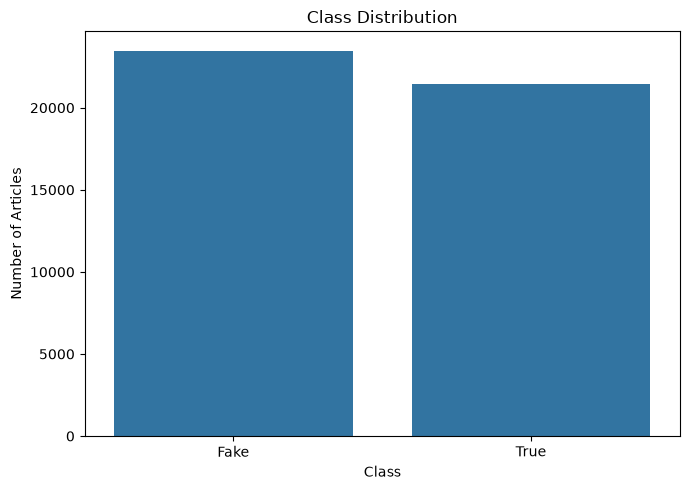

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\class_distribution.png


In [19]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=class_distribution,
    x="label_name",
    y="count"
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Articles")
plt.tight_layout()

class_distribution_path = (
    FIGURES_DIR / "class_distribution.png"
)

plt.savefig(
    class_distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {class_distribution_path}")

## 14. Article Length Analysis

Article length is examined because very short or unusually long texts can influence TF-IDF features and model behaviour.

Both character counts and word counts are calculated for the title and article body.

In [20]:
analysis_df = news_df.copy()

analysis_df["title_clean"] = (
    analysis_df["title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

analysis_df["text_clean"] = (
    analysis_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

analysis_df["title_char_count"] = (
    analysis_df["title_clean"].str.len()
)

analysis_df["text_char_count"] = (
    analysis_df["text_clean"].str.len()
)

analysis_df["title_word_count"] = (
    analysis_df["title_clean"]
    .str.split()
    .str.len()
)

analysis_df["text_word_count"] = (
    analysis_df["text_clean"]
    .str.split()
    .str.len()
)

display(
    analysis_df[
        [
            "title_char_count",
            "text_char_count",
            "title_word_count",
            "text_word_count"
        ]
    ].describe()
)

,title_char_count,text_char_count,title_word_count,text_word_count
count,44898.000000,44898.000000,44898.000000,44898.000000
mean,79.906098,2468.286316,12.453472,405.282284
std,25.348954,2171.649287,4.111476,351.265595
min,8.000000,0.000000,1.000000,0.000000
25%,63.000000,1234.000000,10.000000,203.000000
50%,73.000000,2186.000000,11.000000,362.000000
75%,90.000000,3105.000000,14.000000,513.000000
max,279.000000,51793.000000,42.000000,8135.000000


## 15. Text Length by Class

The distribution of article length is compared between the two dataset labels.

This is exploratory analysis only. Length differences should not automatically be interpreted as evidence that an article is fake or true.

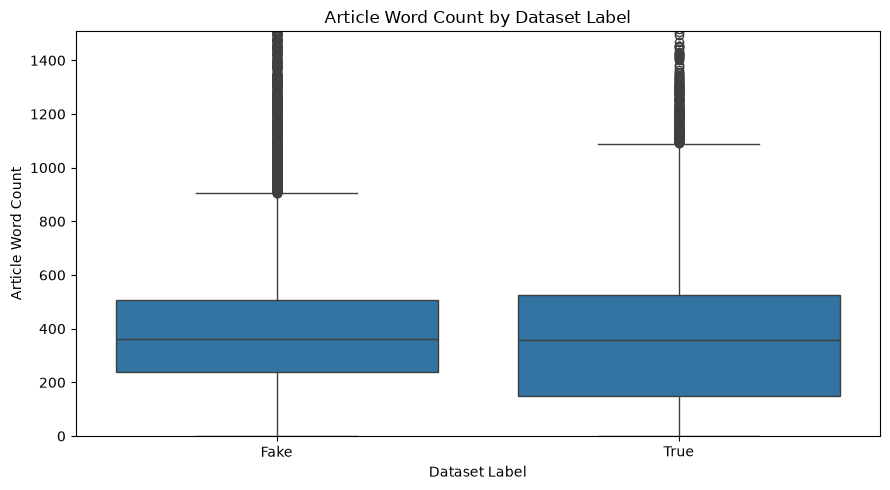

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\text_length_by_label.png


In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=analysis_df,
    x="label_name",
    y="text_word_count"
)

plt.ylim(
    0,
    analysis_df["text_word_count"].quantile(0.99)
)

plt.title("Article Word Count by Dataset Label")
plt.xlabel("Dataset Label")
plt.ylabel("Article Word Count")

plt.tight_layout()

text_length_path = (
    FIGURES_DIR / "text_length_by_label.png"
)

plt.savefig(
    text_length_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {text_length_path}")

## 16. Subject Distribution

The dataset includes a subject/category field.

Subject information is useful for understanding the composition of the dataset, but it will not be blindly included in the primary text classifier. The main NLP model will focus on article content so that it learns linguistic patterns rather than relying on metadata shortcuts.

In [22]:
subject_summary = (
    analysis_df["subject"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .value_counts()
    .rename_axis("subject")
    .reset_index(name="count")
)

display(subject_summary.head(15))

,subject,count
0,politicsNews,11272
1,worldnews,10145
2,News,9050
3,politics,6841
4,left-news,4459
5,Government News,1570
6,US_News,783
7,Middle-east,778


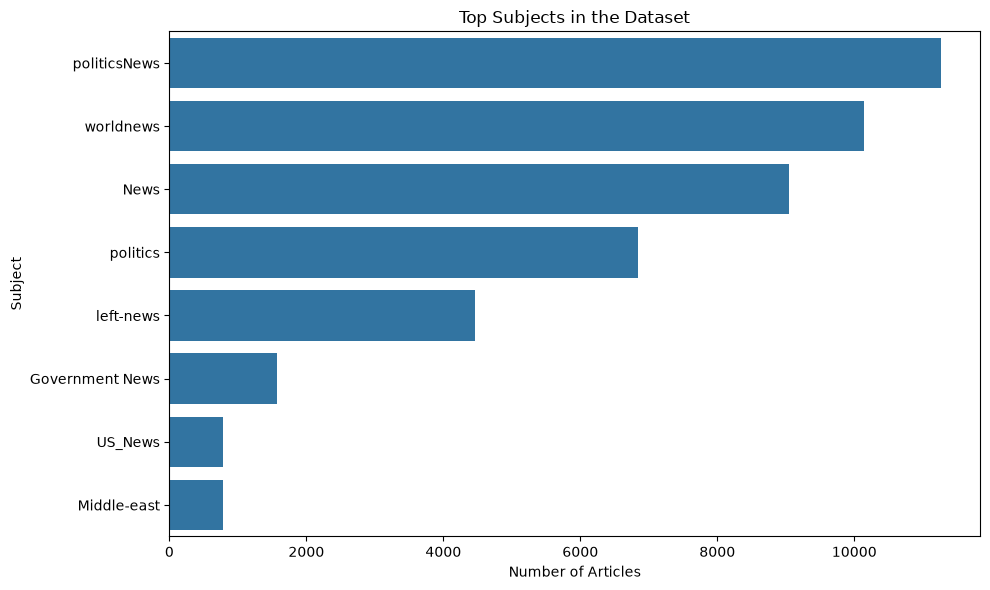

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\top_subjects.png


In [23]:
top_subjects = subject_summary.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_subjects,
    y="subject",
    x="count"
)

plt.title("Top Subjects in the Dataset")
plt.xlabel("Number of Articles")
plt.ylabel("Subject")

plt.tight_layout()

subjects_path = (
    FIGURES_DIR / "top_subjects.png"
)

plt.savefig(
    subjects_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {subjects_path}")

## 17. Date Coverage

The publication date is inspected as metadata.

Date information can reveal the temporal coverage of the dataset and possible formatting issues. It will not be used as a primary text feature in the first modelling pipeline.

In [24]:
analysis_df["date_parsed"] = pd.to_datetime(
    analysis_df["date"],
    errors="coerce"
)

print("Earliest parsed date:")
print(analysis_df["date_parsed"].min())

print("\nLatest parsed date:")
print(analysis_df["date_parsed"].max())

unparsed_dates = (
    analysis_df["date"].notna()
    & analysis_df["date_parsed"].isna()
).sum()

print("\nNon-empty dates that could not be parsed:")
print(unparsed_dates)

Earliest parsed date:
2015-05-01 00:00:00

Latest parsed date:
2017-12-31 00:00:00

Non-empty dates that could not be parsed:
33030


## 18. Preparing the Primary NLP Text

For the first modelling stage, the title and article body are combined into a single text field.

The subject and date fields remain available for analysis but are intentionally excluded from the primary text representation.

This keeps the modelling objective focused on the actual written content of the article.

In [25]:
analysis_df["model_text"] = (
    analysis_df["title_clean"]
    + " "
    + analysis_df["text_clean"]
).str.strip()

analysis_df["model_text_empty"] = (
    analysis_df["model_text"].eq("")
)

print(
    "Rows with no usable title/body text:",
    analysis_df["model_text_empty"].sum()
)

Rows with no usable title/body text: 0


## 19. Quality Cleaning Decisions

The modelling dataset will exclude:

- rows without usable title/body text
- content with conflicting labels
- duplicate normalised article content

The cleaning is deliberately limited at this stage.

Heavy NLP preprocessing such as tokenisation, stop-word handling, n-gram generation, and TF-IDF vectorisation will be performed later inside the modelling pipeline. Keeping those transformations inside the training pipeline helps prevent data leakage.

In [26]:
modeling_df = analysis_df.copy()

initial_rows = len(modeling_df)

# Remove rows without usable text
modeling_df = modeling_df[
    ~modeling_df["model_text_empty"]
].copy()

after_empty_text = len(modeling_df)

# Remove content with conflicting labels
if conflicting_keys:
    modeling_df = modeling_df[
        ~modeling_df["content_quality_key"].isin(
            conflicting_keys
        )
    ].copy()

after_conflicts = len(modeling_df)

# Remove duplicate normalised content
modeling_df = modeling_df.drop_duplicates(
    subset=["content_quality_key"],
    keep="first"
).copy()

after_duplicates = len(modeling_df)

print("Cleaning summary")
print("-" * 40)
print(f"Initial rows:              {initial_rows:,}")
print(f"After empty-text removal:  {after_empty_text:,}")
print(f"After conflict removal:    {after_conflicts:,}")
print(f"After duplicate removal:   {after_duplicates:,}")
print(
    f"Total rows removed:        "
    f"{initial_rows - after_duplicates:,}"
)

Cleaning summary
----------------------------------------
Initial rows:              44,898
After empty-text removal:  44,898
After conflict removal:    44,898
After duplicate removal:   39,100
Total rows removed:        5,798


## 20. Final Modelling Schema

Only the fields required by downstream analysis are retained.

The final dataset contains:

- original title
- original article text
- subject metadata
- date metadata
- numeric target label
- human-readable target label
- combined modelling text

The raw files remain untouched.

In [27]:
FINAL_COLUMNS = [
    "title",
    "text",
    "subject",
    "date",
    "label",
    "label_name",
    "model_text",
]

modeling_df = modeling_df[
    FINAL_COLUMNS
].copy()

print("Final modelling dataset shape:")
print(modeling_df.shape)

print("\nFinal columns:")
print(modeling_df.columns.tolist())

print("\nFinal class distribution:")
display(
    modeling_df["label_name"]
    .value_counts()
    .to_frame("count")
)

Final modelling dataset shape:
(39100, 7)

Final columns:
['title', 'text', 'subject', 'date', 'label', 'label_name', 'model_text']

Final class distribution:


,count
label_name,
True,21195
Fake,17905


## 21. Final Quality Checks

Before saving the prepared dataset, a few assertions are used to catch structural problems early.

These checks are intentionally strict because later notebooks depend on the schema created here.

In [28]:
assert set(modeling_df["label"].unique()).issubset({0, 1})

assert set(
    modeling_df["label_name"].unique()
).issubset({"Fake", "True"})

assert modeling_df["model_text"].notna().all()

assert (
    modeling_df["model_text"]
    .str.strip()
    .ne("")
    .all()
)

assert modeling_df["title"].notna().all() | modeling_df["text"].notna().all()

print("All final modelling dataset checks passed.")

All final modelling dataset checks passed.


## 22. Saving the Data Quality Report

A compact quality report is saved for reproducibility and project documentation.

The report contains summary information rather than the full article text.

In [29]:
quality_report = pd.DataFrame(
    {
        "metric": [
            "initial_rows",
            "final_rows",
            "rows_removed",
            "empty_title_rows",
            "empty_text_rows",
            "conflicting_content_keys",
            "exact_duplicate_rows",
            "normalised_duplicate_rows",
            "fake_articles_final",
            "true_articles_final",
        ],
        "value": [
            initial_rows,
            len(modeling_df),
            initial_rows - len(modeling_df),
            empty_title_count,
            empty_text_count,
            len(conflicting_keys),
            exact_duplicate_count,
            int(duplicate_content_mask.sum()),
            int(
                (modeling_df["label_name"] == "Fake").sum()
            ),
            int(
                (modeling_df["label_name"] == "True").sum()
            ),
        ],
    }
)

quality_report_path = (
    REPORTS_DIR / "data_quality_report.csv"
)

quality_report.to_csv(
    quality_report_path,
    index=False
)

display(quality_report)

print(
    f"\nQuality report saved to:\n{quality_report_path}"
)

,metric,value
0,initial_rows,44898
1,final_rows,39100
2,rows_removed,5798
3,empty_title_rows,0
4,empty_text_rows,631
5,conflicting_content_keys,0
6,exact_duplicate_rows,209
7,normalised_duplicate_rows,11105
8,fake_articles_final,17905
9,true_articles_final,21195



Quality report saved to:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\data_quality_report.csv


## 23. Saving the Prepared Modelling Dataset

The cleaned dataset is saved separately from the raw source files.

This file will be used by the subsequent notebooks so that the same quality decisions are carried consistently through the project.

In [30]:
PROCESSED_DATA_PATH = (
    PROCESSED_DATA_DIR
    / "news_modeling_data.csv"
)

modeling_df.to_csv(
    PROCESSED_DATA_PATH,
    index=False
)

print(
    "Prepared modelling dataset saved to:"
)
print(PROCESSED_DATA_PATH)

Prepared modelling dataset saved to:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\data\processed\news_modeling_data.csv


## 24. Final Dataset Preview

A final preview confirms that the prepared dataset contains the expected modelling fields and usable text.

The article text is intentionally displayed only for a small sample during inspection.

In [31]:
display(
    modeling_df[
        [
            "title",
            "subject",
            "label_name",
            "model_text"
        ]
    ].head(5)
)

,title,subject,label_name,model_text
0,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,News,Fake,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing Donald Trump just couldn t wish all A...
1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation,News,Fake,Drunk Bragging Trump Staffer Started Russian Collusion Investigation House Intelligence Committee Chairman Devin Nun...
2,Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,News,Fake,"Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’ On Friday, it was revealed..."
3,Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES),News,Fake,"Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES) On Christmas day, Donald Trump announc..."
4,Pope Francis Just Called Out Donald Trump During His Christmas Speech,News,Fake,Pope Francis Just Called Out Donald Trump During His Christmas Speech Pope Francis used his annual Christmas Day mes...


## 25. Notebook Summary

This notebook established the data foundation for the Fake News Detection project.

Key outcomes:

- loaded the raw Fake and True article datasets
- standardised the source schema
- created the target labels
- inspected missing and empty values
- checked exact and normalised duplicates
- identified conflicting content labels
- analysed class distribution
- examined article length
- reviewed subject and date coverage
- created the combined `model_text` field
- removed unusable, conflicting, and duplicate content
- saved the final modelling dataset
- saved a data quality report and exploratory figures

The next notebook will focus on exploratory text analysis and NLP-oriented dataset inspection. No TF-IDF or machine-learning model is fitted in this notebook.

In [32]:
print("=" * 60)
print("NOTEBOOK 1 COMPLETED SUCCESSFULLY")
print("=" * 60)

print(f"\nFinal modelling rows: {len(modeling_df):,}")
print(f"Final columns: {len(modeling_df.columns)}")

print("\nClass distribution:")
print(modeling_df["label_name"].value_counts())

print("\nSaved files:")
print(f"- {PROCESSED_DATA_PATH}")
print(f"- {quality_report_path}")
print(f"- {class_distribution_path}")
print(f"- {text_length_path}")
print(f"- {subjects_path}")

NOTEBOOK 1 COMPLETED SUCCESSFULLY

Final modelling rows: 39,100
Final columns: 7

Class distribution:
label_name
True    21195
Fake    17905
Name: count, dtype: int64

Saved files:
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\data\processed\news_modeling_data.csv
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\data_quality_report.csv
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\class_distribution.png
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\text_length_by_label.png
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\top_subjects.png
